# Sepsis v2: структура, повторные состояния, интенсивности и цензура

Более подробный реальный эксперимент: фиксируем правила преобразования журнала,
разделяем объекты на train/test, обнаруживаем train DFG, оцениваем exponential min-time
модель с цензурой и без неё, проверяем NLL на **всём** holdout и прогнозируем путь до выписки.
Истинных клинических интенсивностей здесь нет: оцениваем модель наблюдаемой записи.
Основной запуск не требует PM4Py, Graphviz и lifelines.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "dima/survpm/src/survpm").is_dir())
sys.path.insert(0, str(ROOT / "dima/survpm/src"))
from survpm import (EventLog, Network, ProcessModel, ExponentialTransitionModel,
                    ObjectStream, Simulator, Forecaster, discover,
                    DirectlyFollowsBackend, evaluate, compare, compare_networks)
from survpm import datasets
from survpm.log import censoring_summary
from survpm.viz import MatplotlibVisualizer
pd.set_option("display.precision", 4, "display.max_columns", 20)

## 1. Журнал и правила наблюдения

Используем реальный grouped CSV. По умолчанию `Examination` остаётся состоянием,
а числовые анализы дополнительно хранятся в measurements. Признаки в этой модели не участвуют;
персонализированная log-rate регрессия показана в `features_sepsis.ipynb`.

`simultaneous` склеивает только совпадающие по состоянию и времени строки; поздний повтор
остаётся петлёй. `collapse` убирает всю серию одного состояния. Трасса начинается с первой
Registration и завершается при первом Discharge. Конец незавершённого наблюдения — последняя
доступная запись события/замера; независимый follow-up в исходном файле не задан.
Никакие дополнительные дни наблюдения не придумываются.

In [2]:
LOG_PATH = ROOT / "Med_Eremina/Sepsis Cases - Event Log_grouped.csv"
CSV_SEP = ","
MAPPING = {"case_id": "case_id", "activity": "event_group", "timestamp": "time:timestamp"}
START, TERMINAL = "Registration", "Discharge"
# Для своего CSV измените также словарь состояний и правила подготовки.
STATE_VOCABULARY = ["Registration", "Examination", "Treatment", "Admission", "Discharge", "Return"]
REPEATS = "simultaneous"       # поздние повторы дают self-loop; также collapse / keep
MIN_DURATION_DAYS = 1 / 1440  # технический нижний порог: одна минута
TRAIN_RATIO = .75
SEED = 2026

raw_log = datasets.load_sepsis_log(LOG_PATH)
print("Исходных событий:", len(raw_log.events), "; замеров:", len(raw_log.measurements))

def take_cases(log, ids):
    ids = set(ids)
    return EventLog(log.events.loc[log.events.case_id.isin(ids)].copy(),
                    log.cases.loc[log.cases.index.isin(ids)].copy(),
                    log.measurements.loc[log.measurements.case_id.isin(ids)].copy(),
                    log.last_seen.loc[log.last_seen.index.isin(ids)].copy(),
                    log.observation.loc[log.observation.case_id.isin(ids)].copy(), log.rules)

def split_cases(log, ratio=TRAIN_RATIO, seed=SEED):
    ids = log.events.case_id.drop_duplicates().to_numpy()
    ids = np.random.default_rng(seed).permutation(ids)
    boundary = int(len(ids) * ratio)
    parts = take_cases(log, ids[:boundary]), take_cases(log, ids[boundary:])
    assert set(parts[0].cases.index).isdisjoint(parts[1].cases.index)
    return parts

# Это структурный prior по заранее объявленному словарю, а не discovery по test.
# Он разрешает все направленные пары, включая петли, кроме исходов из терминала.
envelope = Network.from_edges([(s, d) for s in STATE_VOCABULARY if s != TERMINAL
                               for d in STATE_VOCABULARY], starts=[START], terminals=[TERMINAL])

Исходных событий: 13112 ; замеров: 7938


In [3]:
rules = dict(starts=[START], terminals=[TERMINAL], repeats=REPEATS,
             min_duration=MIN_DURATION_DAYS)
log = raw_log.prepare(rules)
unknown = set(log.events.activity) - set(STATE_VOCABULARY)
assert not unknown, f"Добавьте состояния в явный словарь: {unknown}"
train, test = split_cases(log)
train_iv, test_iv = train.intervals(), test.intervals()
print("Объектов train/test:", len(train.cases), len(test.cases))
print("Событий train/test:", len(train.events), len(test.events))
display(log.observation.groupby(["event", "reason"]).size().rename("cases"))
display(train_iv.head())
# Фактическое время между последним состоянием и концом наблюдения, до численного floor.
last_entry = log.events.groupby("case_id").timestamp.max()
obs = log.observation.set_index("case_id")
actual_tail = ((obs.end - last_entry) / pd.Timedelta(days=1)).loc[obs.event.eq(0)]
print("Незавершённых объектов:", len(actual_tail),
      "; с положительным фактическим хвостом:", int(actual_tail.gt(0).sum()))
display(censoring_summary(train_iv))

Объектов train/test: 787 263
Событий train/test: 6225 2100
Незавершённых объектов: 268 ; с положительным фактическим хвостом: 0


event  reason
0      lost      268
1                782
Name: cases, dtype: int64

,case_id,src,dst,duration,observed,reason,enter
0,A,Registration,Examination,0.0079,True,,2014-10-22 09:15:41+00:00
1,A,Examination,Treatment,0.1089,True,,2014-10-22 09:27:00+00:00
2,A,Treatment,Admission,0.0066,True,,2014-10-22 12:03:47+00:00
3,A,Admission,Examination,1.7824,True,,2014-10-22 12:13:19+00:00
4,A,Examination,Examination,2.0000,True,,2014-10-24 07:00:00+00:00


,src,n_visits,n_completed,p_completed,q_censored,n_lost,q_lost
0,Admission,974,963,0.9887,0.0113,11,0.0113
1,Examination,2755,2661,0.9659,0.0341,94,0.0341
2,Registration,787,759,0.9644,0.0356,28,0.0356
3,Treatment,1127,1055,0.9361,0.0639,72,0.0639


## 2. Train DFG и явно заданный структурный prior

DFG — результат discovery только по train. Отдельно для оценки используем объявленный заранее
полный граф по известному словарю состояний. Это широкий prior, **не восстановленная истинная
структура**: все возможные направления и петли разрешены, исходы из Discharge запрещены.
Сравнение ниже показывает долю рёбер prior, которую поддерживает train; recall относительно
prior не является качеством обнаружения клинического процесса. Ребро без train-событий
получает нулевую интенсивность, в том числе если оно встретится на test.

In [4]:
found = discover(train, DirectlyFollowsBackend(starts=[START], terminals=[TERMINAL]))
print("Train DFG рёбер:", len(found.edges), "; разрешено prior:", len(envelope.edges))
print("Диагностика DFG:")
display(found.validate())
aware = ProcessModel(envelope).fit(train)
naive = ProcessModel(envelope).fit(train, use_censoring=False)
models = {"censor_aware": aware, "naive_completed_only": naive}
rates = aware.edges_table().rename(columns={"rate": "aware_rate"})
rates = rates.merge(naive.edges_table()[["src", "dst", "rate"]].rename(columns={"rate": "naive_rate"}),
                    on=["src", "dst"], validate="one_to_one")
rates["clock_mean_days"] = np.divide(1., rates.aware_rate,
    out=np.full(len(rates), np.inf), where=rates.aware_rate.to_numpy() > 0)
rates["rate_difference"] = rates.aware_rate - rates.naive_rate
display(rates)
print("Нулевых clocks:", int(rates.aware_rate.eq(0).sum()))
print("Максимальная разность rate:", rates.rate_difference.abs().max())

Train DFG рёбер: 15 ; разрешено prior: 30
Диагностика DFG:
Нулевых clocks: 15
Максимальная разность rate: 0.05583753192702545


,state,issue


,src,dst,n_completed,n_visits,aware_rate,p,mean_days,naive_rate,clock_mean_days,rate_difference
0,Registration,Registration,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
1,Registration,Examination,569,787,40.3944,0.7497,0.0186,40.4503,0.0248,-5.5838e-02
2,Registration,Treatment,186,787,13.2045,0.2451,0.0186,13.2228,0.0757,-1.8253e-02
3,Registration,Admission,4,787,0.2840,0.0053,0.0186,0.2844,3.5215,-3.9253e-04
4,Registration,Discharge,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
5,Registration,Return,0,787,0.0000,0.0000,0.0186,0.0000,inf,0.0000e+00
6,Examination,Registration,0,2755,0.0000,0.0000,1.1846,0.0000,inf,0.0000e+00
7,Examination,Examination,1291,2755,0.4096,0.4852,1.1846,0.4096,2.4416,-8.4820e-06
8,Examination,Treatment,524,2755,0.1662,0.1969,1.1846,0.1662,6.0155,-3.4428e-06
9,Examination,Admission,378,2755,0.1199,0.1421,1.1846,0.1199,8.3389,-2.4835e-06


Сравнение с объявленным prior (не клиническая истина):
precision
recall
f1
missing
extra


1.0

0.5

0.6666666666666666

,src,dst
0,Admission,Registration
1,Admission,Return
2,Examination,Registration
3,Examination,Return
4,Registration,Discharge
5,Registration,Registration
6,Registration,Return
7,Return,Admission
8,Return,Discharge
9,Return,Examination


,src,dst


,src,dst,success,status,n_completed
0,Registration,Registration,True,no_events,0
1,Registration,Examination,True,ok,569
2,Registration,Treatment,True,ok,186
3,Registration,Admission,True,ok,4
4,Registration,Discharge,True,no_events,0
5,Registration,Return,True,no_events,0
6,Examination,Registration,True,no_events,0
7,Examination,Examination,True,ok,1291
8,Examination,Treatment,True,ok,524
9,Examination,Admission,True,ok,378


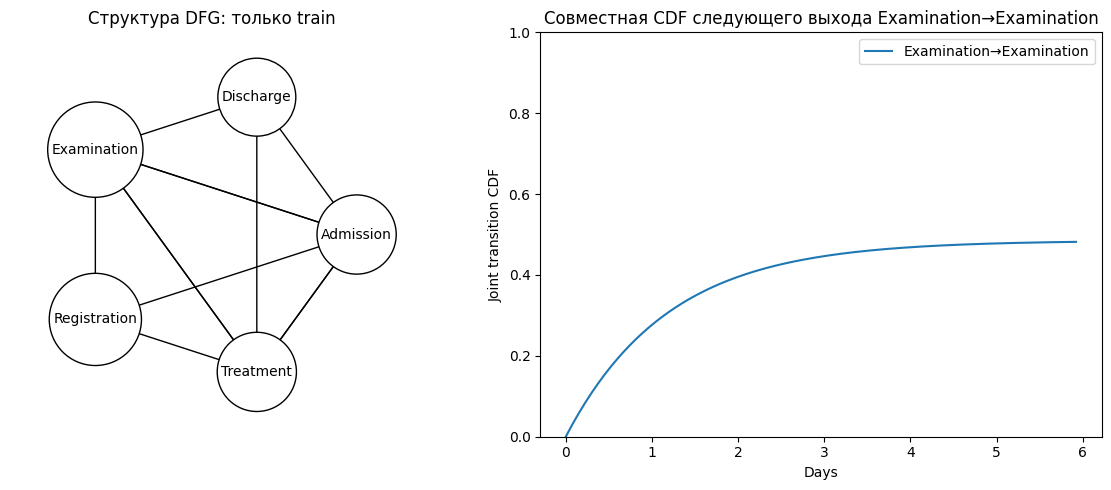

In [5]:
print("Сравнение с объявленным prior (не клиническая истина):")
for key, value in compare_networks(envelope, found).items():
    print(key)
    display(value)
display(aware.transitions.diagnostics)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
found.plot(ax=axes[0])
axes[0].set_title("Структура DFG: только train")
# Наиболее частый train-переход; выбор не использует test.
edge = tuple(rates.sort_values("n_completed", ascending=False).iloc[0][["src", "dst"]])
viz = MatplotlibVisualizer()
total = sum(aware.transition_parameters(edge[0]).values())
times = np.linspace(0, 5/total, 160)
viz.plot_edge_curves(aware, edge, times, ax=axes[1])
axes[1].set_title(f"Совместная CDF следующего выхода {edge[0]}→{edge[1]}")
axes[1].legend()
fig.tight_layout()

## 3. Интенсивность часов и наблюдаемое время до выхода

`rate` — интенсивность независимого часа; среднее его срабатывания `1/rate`.
Минимум по исходящим часам имеет интенсивность `sum(rate)` и среднее `1/sum(rate)`;
вероятность направления `rate/sum(rate)`. На предыдущем рисунке совместная CDF
следующего перехода стремится к этой вероятности.

Ниже плотность минимума показана отдельно от плотностей часов. Гистограмма — только
завершённые train-ожидания из выбранного состояния, поэтому подвержена отбору наблюдением;
она описательна и не служит проверкой отсутствия цензуры. Плотности отдельных часов
не накладываются на гистограмму выбранных направлений.

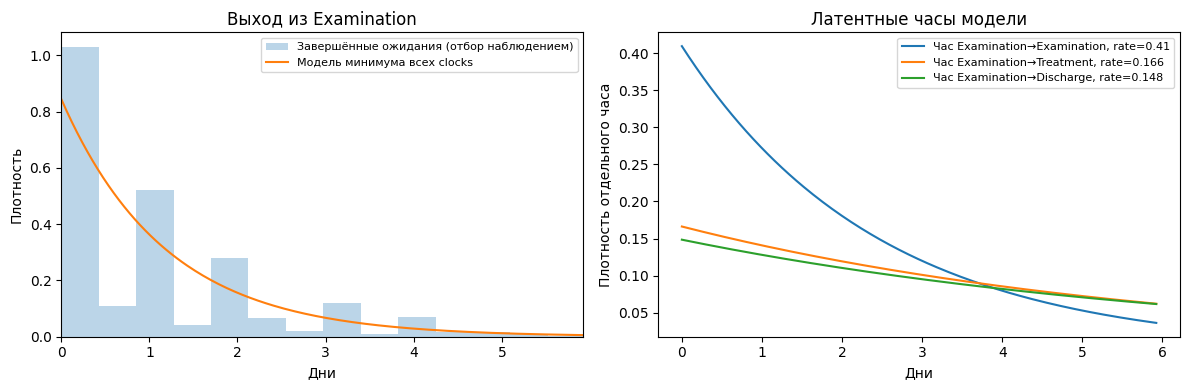

In [6]:
src = edge[0]
source_iv = train_iv.loc[train_iv.src.eq(src)]
source_rates = aware.transition_parameters(src)
selected = sorted(source_rates, key=source_rates.get, reverse=True)[:3]
total = sum(source_rates.values())
times = np.linspace(0, 5/total, 200)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(source_iv.loc[source_iv.observed, "duration"], bins=45, density=True,
             alpha=.3, label="Завершённые ожидания (отбор наблюдением)")
axes[0].plot(times, total*np.exp(-total*times), label="Модель минимума всех clocks")
axes[0].set(xlim=(0, times[-1]), xlabel="Дни", ylabel="Плотность", title=f"Выход из {src}")
axes[0].legend(fontsize=8)
for dst in selected:
    rate = source_rates[dst]
    axes[1].plot(times, rate*np.exp(-rate*times), label=f"Час {src}→{dst}, rate={rate:.3g}")
axes[1].set(xlabel="Дни", ylabel="Плотность отдельного часа", title="Латентные часы модели")
axes[1].legend(fontsize=8)
fig.tight_layout()

## 4. Полный holdout NLL и диагностика покрытия

Считаем переходы с нулевым train-rate и число затронутых целых объектов. В основной
оценке остаются **все** test-объекты: неизвестный переход даёт бесконечный NLL.
Сглаживание не вводится. Временной перенос и клиническая калибровка этим случайным
holdout не проверяются. NLL — отрицательный логарифм плотности, поэтому может быть отрицательным.

In [7]:
# Проверяем весь holdout: ни строки, ни целые объекты не исключаем.
positive_train_edges = {e for e, rate in aware.transitions.rates.items() if rate > 0}
observed_test = test_iv.loc[test_iv.observed, ["case_id", "src", "dst"]].copy()
observed_test["zero_train_rate"] = [
    (s, d) not in positive_train_edges for s, d in observed_test[["src", "dst"]].itertuples(index=False, name=None)]
unseen = observed_test.loc[observed_test.zero_train_rate]
print("Переходов с rate=0 на test:", len(unseen),
      "; затронуто целых объектов:", unseen.case_id.nunique(), "из", len(test.cases))
display(unseen.groupby(["src", "dst"]).size().rename("test_count").reset_index())
full_holdout = compare(models, test, metrics=["nll"])
display(full_holdout)
assert test_iv.case_id.nunique() == len(test.cases)

Переходов с rate=0 на test: 0 ; затронуто целых объектов: 0 из 263


,src,dst,test_count


,model,metric,value
0,censor_aware,nll_per_interval,1.0628
1,censor_aware,nll_per_trace,7.6777
2,naive_completed_only,nll_per_interval,1.0627
3,naive_completed_only,nll_per_trace,7.6776


## 5. Чувствительность к повторам и прозрачным измерениям

Две конфигурации `simultaneous`/`collapse` и дополнительная `Examination`-transparent версия
используют те же train/test ID. В прозрачной версии анализы продлевают last_seen и могут
дать положительный цензурированный хвост после последнего состояния. Это изменение
определения состояний, а не новый источник follow-up. NLL различных определений интервала
не следует ранжировать как оценки на одном и том же пространстве исходов.

Численный floor одной минуты применяется к нулевым и коротким ожиданиям.
Сравниваем число петель, реальную экспозицию цензуры, максимальное отличие rates
и полный NLL внутри каждой конфигурации. Нулевые rates и inf сохраняются в выводе.

In [8]:
train_ids, test_ids = set(train.cases.index), set(test.cases.index)
transparent_raw = datasets.load_sepsis_log(LOG_PATH, measurement_activities=["Examination"])
scenarios = [("full_simultaneous", raw_log, "simultaneous"),
             ("full_collapse", raw_log, "collapse"),
             ("transparent_simultaneous", transparent_raw, "simultaneous")]
scenario_rows = []
for scenario, source, repeats in scenarios:
    scenario_log = source.prepare(dict(rules, repeats=repeats))
    scenario_train = take_cases(scenario_log, train_ids)
    scenario_test = take_cases(scenario_log, test_ids)
    scenario_iv = scenario_train.intervals()
    last = scenario_train.events.groupby("case_id").timestamp.max()
    observation = scenario_train.observation.set_index("case_id")
    actual = ((observation.end-last)/pd.Timedelta(days=1)).loc[observation.event.eq(0)]
    fitted = ProcessModel(envelope).fit(scenario_train)
    completed = ProcessModel(envelope).fit(scenario_train, use_censoring=False)
    rate_gap = max(abs(fitted.transitions.rates[e] - completed.transitions.rates[e])
                   for e in fitted.transitions.rates)
    for name, model in [("censor_aware", fitted), ("naive_completed_only", completed)]:
        score = evaluate(model, scenario_test, metrics=["nll"])["nll"].set_index("metric").value
        scenario_rows.append(dict(scenario=scenario, model=name,
            train_intervals=len(scenario_iv), test_objects=len(scenario_test.cases),
            train_self_loops=int((scenario_iv.observed & scenario_iv.src.eq(scenario_iv.dst)).sum()),
            actual_censor_exposure_days=float(actual.sum()), positive_censor_tails=int(actual.gt(0).sum()),
            zero_rate_edges=sum(v == 0 for v in model.transitions.rates.values()),
            max_rate_gap=rate_gap, full_test_nll=score["nll_per_interval"]))
scenario_results = pd.DataFrame(scenario_rows)
display(scenario_results)

,scenario,model,train_intervals,test_objects,train_self_loops,actual_censor_exposure_days,positive_censor_tails,zero_rate_edges,max_rate_gap,full_test_nll
0,full_simultaneous,censor_aware,5643,263,1843,0.0000,0,15,0.0558,1.0628
1,full_simultaneous,naive_completed_only,5643,263,1843,0.0000,0,15,0.0558,1.0627
2,full_collapse,censor_aware,3800,263,0,6.5958,54,18,0.4721,0.8887
3,full_collapse,naive_completed_only,3800,263,0,6.5958,54,18,0.4721,0.8868
4,transparent_simultaneous,censor_aware,2888,263,866,6.7913,93,22,0.4816,0.6387
5,transparent_simultaneous,naive_completed_only,2888,263,866,6.7913,93,22,0.4816,0.6372


## 6. Весь путь до Discharge и описательная эмпирическая кривая

Прогноз выбранного test-объекта в момент регистрации использует только историю до `as_of`;
будущие реальные события и анализы недоступны. Без признаков любой объект в том же состоянии
получает тот же закон будущего. По 300 путям строим survival на 30 дней и ограниченное среднее.

Эмпирическая KM всех test-объектов ниже — описательное сравнение с моделью от регистрации,
не метрика калибровки. Для KM нужна независимая цензура, которую реальный журнал не гарантирует;
совпадающие времена обрабатываем с событиями до снятия цензурированных из группы риска.

,horizon,survival,cdf
0,0.0,1.0000,0.0000
1,1.0,0.8800,0.1200
2,3.0,0.6833,0.3167
3,7.0,0.3767,0.6233
4,14.0,0.1133,0.8867
5,30.0,0.0200,0.9800


,restricted_mean_time,probability_unfinished
0,6.8634,0.02


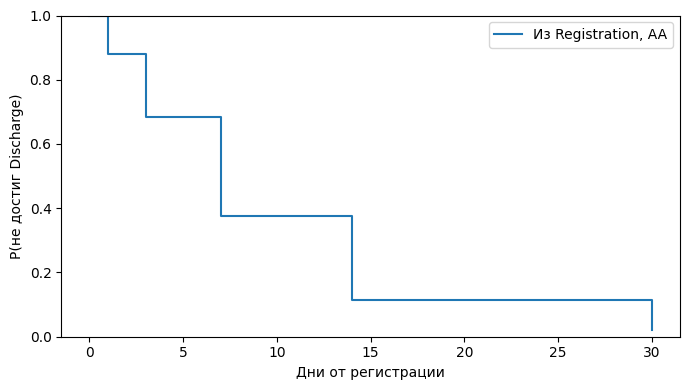

In [9]:
case_id = test.events.case_id.iloc[0]
entry = test.events.loc[test.events.case_id.eq(case_id), "timestamp"].min()
times = np.array([0., 1., 3., 7., 14., 30.])
forecaster = Forecaster(aware, n_paths=300, seed=42)
survival = forecaster.survival(test, entry, times, case_id=case_id)
display(survival)
display(pd.DataFrame([forecaster.expected_time(test, entry, horizon=30., case_id=case_id)]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.step(survival.horizon, survival.survival, where="post", label=f"Из Registration, {case_id}")
ax.set(xlabel="Дни от регистрации", ylabel="P(не достиг Discharge)", ylim=(0, 1))
ax.legend()
fig.tight_layout()

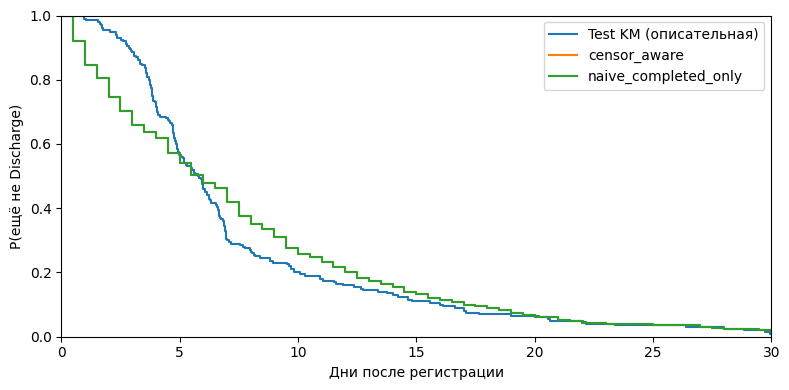

In [10]:
def kaplan_meier(duration, event):
    duration, event = np.asarray(duration, float), np.asarray(event, bool)
    times, values, value = [0.], [1.], 1.
    for time in np.unique(duration[event]):
        at_risk = np.count_nonzero(duration >= time)
        deaths = np.count_nonzero((duration == time) & event)
        value *= 1 - deaths / at_risk
        times.append(time)
        values.append(value)
    return np.asarray(times), np.asarray(values)

obs = test.observation.set_index("case_id")
entry_by_case = test.events.groupby("case_id").timestamp.min()
duration = (obs.end - entry_by_case)/pd.Timedelta(days=1)
km_time, km_value = kaplan_meier(duration, obs.event)
fig, ax = plt.subplots(figsize=(8, 4))
ax.step(km_time, km_value, where="post", label="Test KM (описательная)")
for name, model in models.items():
    curve = Forecaster(model, n_paths=300, seed=81).survival(
        test, entry, np.linspace(0, 30, 61), case_id=case_id)
    ax.step(curve.horizon, curve.survival, where="post", label=name)
ax.set(xlim=(0, 30), ylim=(0, 1), xlabel="Дни после регистрации", ylabel="P(ещё не Discharge)")
ax.legend()
fig.tight_layout()

## 7. Что можно заключать по текущему запуску

Численные результаты берутся только из выполненных ячеек. Таблицы показывают наблюдаемую
структуру, оценённые clocks, поддержку редких направлений и NLL всех отложенных объектов.
При нулевом фактическом хвосте aware и naive могут практически совпадать: такой журнал
не позволяет продемонстрировать пользу известного длительного follow-up. Добавлять его
искусственно в реальный опыт нельзя; соответствующий контролируемый опыт есть в synthetic notebook.

Exponential min-time — сильное модельное допущение. Частые исследования и повторные записи
создают наблюдательный процесс, который не обязан совпадать с клиническими переходами.
Общий Petri net, причинные медицинские выводы, AIC по разным семействам, IBS и старые allmetrics
здесь не рассчитываются. Параллелизм и Inductive Miner не заявляются. Результаты автоматически
не экспортируются, исторические рисунки в `notebooks/output` к этому запуску не относятся.